# **Lab 7(B) - Mathematical and Statistical Filters**

### Name: Abdullah Alnaji
### ID: 2240007157
Each filter suits a specific type of noise. The original notebook used Gaussian noise with every filter; here we apply each filter to the noise it is designed for and compare using **PSNR** (higher is better).

In [1]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)

def show(imgs, titles, figsize=None, cols=None):
    n = len(imgs); cols = cols or n; rows = int(np.ceil(n/cols))
    plt.figure(figsize=figsize or (4.5*cols, 4.5*rows))
    for i,(im,t) in enumerate(zip(imgs,titles)):
        plt.subplot(rows, cols, i+1); plt.imshow(im, cmap='gray', vmin=0, vmax=255)
        plt.title(t, fontsize=10); plt.axis('off')
    plt.tight_layout(); plt.show()

def psnr(a, b):
    # Peak Signal-to-Noise Ratio between a reference image a and an image b
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64))**2)
    return float('inf') if mse == 0 else 10*np.log10(255**2/mse)

## 1) Adding Noise to an Image

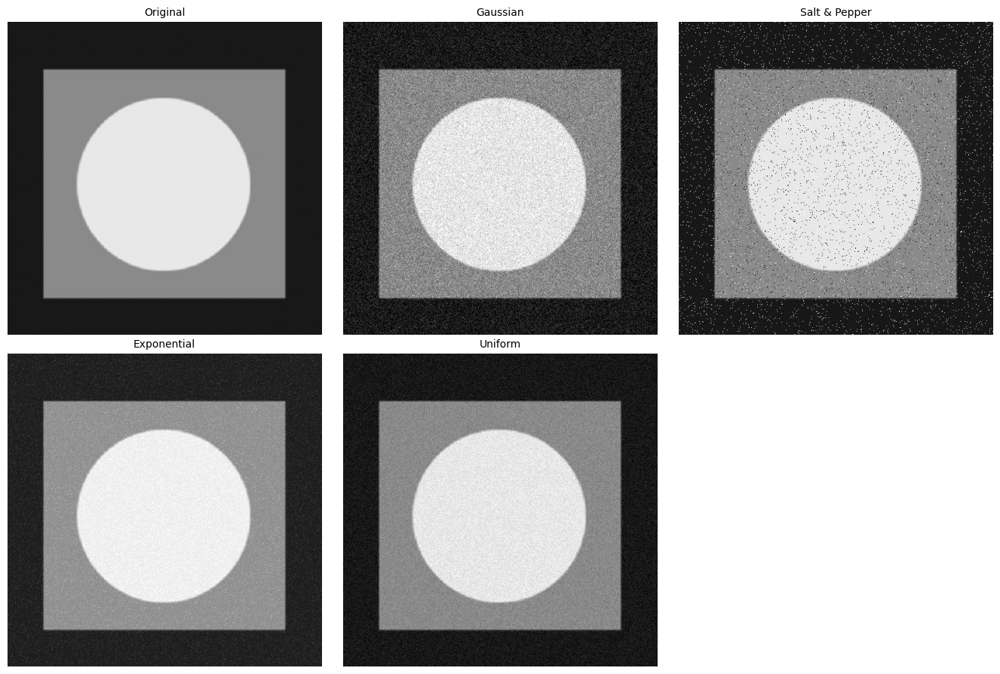

In [2]:
imgPath = 'noise.jpg'
img = cv2.imread(imgPath, 0)
assert img is not None, "noise.jpg not found"

def add_noise(image, noise_type):
    row, col = image.shape

    if noise_type == "gaussian":
        mean, var = 0, 0.01
        sigma = var**0.5
        gauss = np.random.normal(mean, sigma, (row, col))
        noisy = image / 255 + gauss
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)

    elif noise_type == "salt_pepper":
        s_vs_p, amount = 0.5, 0.04
        noisy = np.copy(image)
        num_salt = int(np.ceil(amount * image.size * s_vs_p))
        coords = [np.random.randint(0, i, num_salt) for i in image.shape]   # use i (not i-1) to include the last row/col
        noisy[tuple(coords)] = 255
        num_pepper = int(np.ceil(amount * image.size * (1.0 - s_vs_p)))
        coords = [np.random.randint(0, i, num_pepper) for i in image.shape]
        noisy[tuple(coords)] = 0
        return noisy

    elif noise_type == "exponential":
        expo = np.random.exponential(scale=10.0, size=(row, col))
        return np.clip(image + expo, 0, 255).astype(np.uint8)

    elif noise_type == "uniform":
        uni = np.random.uniform(-20, 20, (row, col))
        return np.clip(image + uni, 0, 255).astype(np.uint8)

np.random.seed(0)
noise_gauss = add_noise(img, "gaussian")
noise_sp    = add_noise(img, "salt_pepper")
noise_expo  = add_noise(img, "exponential")
noise_uni   = add_noise(img, "uniform")

show([img, noise_gauss, noise_sp, noise_expo, noise_uni],
     ['Original','Gaussian','Salt & Pepper','Exponential','Uniform'], cols=3)

## 2) Arithmetic Mean Filter

**Fix:** in the original notebook, Method 2 was applied to `img` (the clean image!) instead of the noisy one, so it removed no noise. Here it is applied to `noise_gauss`. We also use `plt.imshow` instead of `display` so the image is actually shown rather than a raw array.

Both methods give (almost) the same result: True


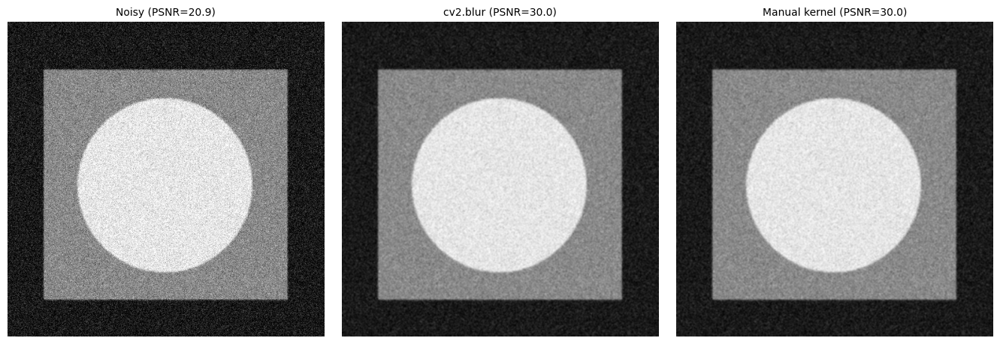

In [3]:
# Method 1: built-in OpenCV function
filtered_img = cv2.blur(noise_gauss, (3, 3))

# Method 2: manual kernel (matrix of 1/9)
kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
arithmetic_mean_manual = cv2.filter2D(noise_gauss, -1, kernel)   # noise_gauss, not img

print("Both methods give (almost) the same result:", np.abs(filtered_img.astype(int) - arithmetic_mean_manual.astype(int)).max() <= 1)
show([noise_gauss, filtered_img, arithmetic_mean_manual],
     [f'Noisy (PSNR={psnr(img,noise_gauss):.1f})',
      f'cv2.blur (PSNR={psnr(img,filtered_img):.1f})',
      f'Manual kernel (PSNR={psnr(img,arithmetic_mean_manual):.1f})'])

## 3) Geometric Mean Filter

$$\hat f(x,y)=\Big[\prod_{(s,t)\in S_{xy}} g(s,t)\Big]^{1/mn}$$

Implemented as the mean of logarithms followed by exp. It preserves detail better than the arithmetic mean and suits Gaussian/Uniform noise. (It is unsuitable for Salt & Pepper because a 0 pixel drives the result to 0.)

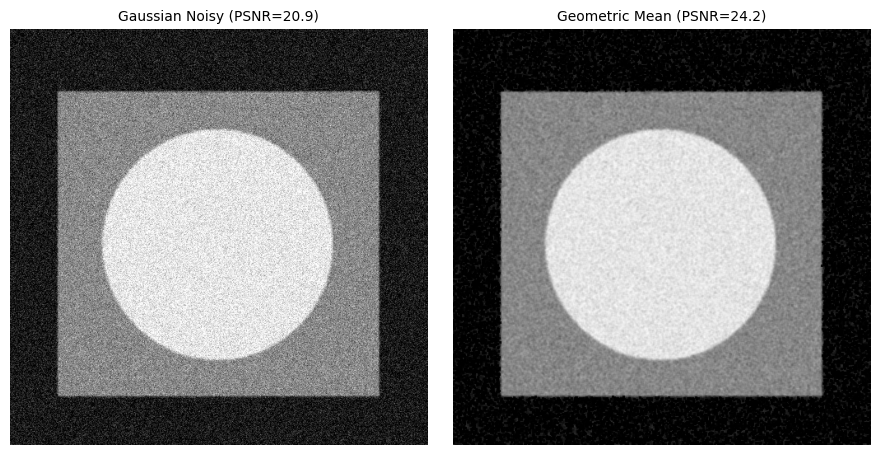

In [4]:
def geometric_mean_filter(image, kernel_size=3):
    img_float = image.astype(np.float64) + 1e-6      # epsilon avoids log(0)
    log_img = np.log(img_float)
    kernel = np.ones((kernel_size, kernel_size), np.float64) / (kernel_size**2)
    mean_log = cv2.filter2D(log_img, -1, kernel)
    return np.clip(np.exp(mean_log), 0, 255).astype(np.uint8)

res = geometric_mean_filter(noise_gauss, 3)
show([noise_gauss, res], [f'Gaussian Noisy (PSNR={psnr(img,noise_gauss):.1f})', f'Geometric Mean (PSNR={psnr(img,res):.1f})'])

## 4) Harmonic Mean Filter

$$\hat f=\frac{mn}{\sum 1/g(s,t)}$$

Works well with **Salt** noise (a white pixel gives 1/255 ≈ 0 so it is ignored) and with Gaussian noise, but it **fails** with Pepper (a 0 pixel gives a huge 1/ε so the output becomes 0).

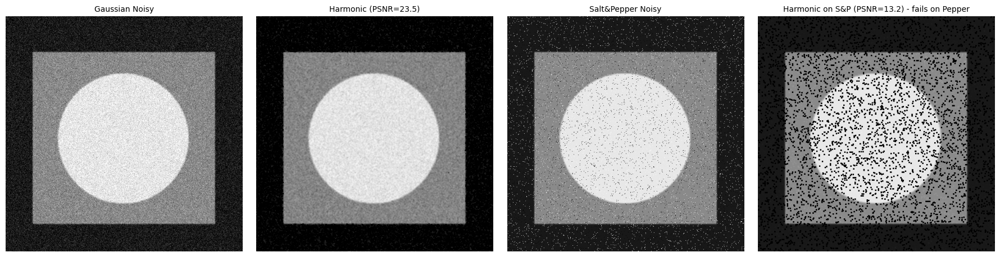

In [5]:
def harmonic_mean_filter(image, kernel_size=3):
    img_float = image.astype(np.float64) + 1e-6
    reciprocal_img = 1.0 / img_float
    kernel = np.ones((kernel_size, kernel_size), np.float64)
    sum_reciprocal = cv2.filter2D(reciprocal_img, -1, kernel)
    n = kernel_size * kernel_size
    return np.clip(n / sum_reciprocal, 0, 255).astype(np.uint8)

res_g = harmonic_mean_filter(noise_gauss, 3)
res_sp = harmonic_mean_filter(noise_sp, 3)
show([noise_gauss, res_g, noise_sp, res_sp],
     ['Gaussian Noisy', f'Harmonic (PSNR={psnr(img,res_g):.1f})', 'Salt&Pepper Noisy', f'Harmonic on S&P (PSNR={psnr(img,res_sp):.1f}) - fails on Pepper'], cols=4, figsize=(18,4.5))

## 5) Contra-Harmonic Mean Filter

$$\hat f=\frac{\sum g^{Q+1}}{\sum g^{Q}}$$

- **Q > 0**: removes **Pepper** noise (black dots)
- **Q < 0**: removes **Salt** noise (white dots)
- **Q = 0**: arithmetic mean, **Q = -1**: harmonic mean

**Note:** to see the effect clearly we need an image with only one type of noise, so we create a Pepper-only image and a Salt-only image. To avoid overflow with large powers we normalize values to (0, 1] before computing (the ratio scales linearly, so it is unaffected).

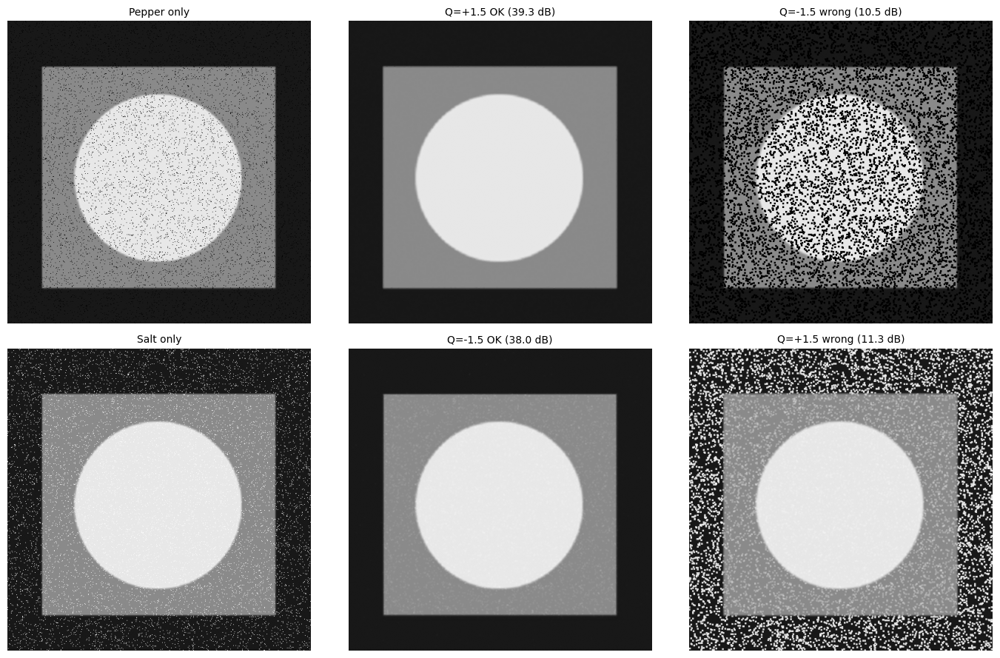

In [6]:
def contra_harmonic_mean(image, kernel_size=3, Q=0):
    # Normalizing to (0,1] prevents overflow; the ratio sum(g^(Q+1))/sum(g^Q) scales linearly
    f = image.astype(np.float64) / 255.0 + 1e-3
    kernel = np.ones((kernel_size, kernel_size), np.float64)
    num = cv2.filter2D(np.power(f, Q + 1), -1, kernel)
    den = cv2.filter2D(np.power(f, Q),     -1, kernel)
    out = (num / den - 1e-3) * 255.0
    return np.clip(out, 0, 255).astype(np.uint8)

def only_pepper(image, amount=0.04):
    out = image.copy(); n = int(amount*image.size)
    out[tuple(np.random.randint(0, s, n) for s in image.shape)] = 0
    return out

def only_salt(image, amount=0.04):
    out = image.copy(); n = int(amount*image.size)
    out[tuple(np.random.randint(0, s, n) for s in image.shape)] = 255
    return out

pepper_img = only_pepper(img); salt_img = only_salt(img)

p_fixed = contra_harmonic_mean(pepper_img, 3, Q=1.5)    # Q>0 removes Pepper
s_fixed = contra_harmonic_mean(salt_img,   3, Q=-1.5)   # Q<0 removes Salt
p_wrong = contra_harmonic_mean(pepper_img, 3, Q=-1.5)   # opposite sign: amplifies Pepper
s_wrong = contra_harmonic_mean(salt_img,   3, Q=1.5)    # opposite sign: amplifies Salt

show([pepper_img, p_fixed, p_wrong, salt_img, s_fixed, s_wrong],
     ['Pepper only', f'Q=+1.5 OK ({psnr(img,p_fixed):.1f} dB)', f'Q=-1.5 wrong ({psnr(img,p_wrong):.1f} dB)',
      'Salt only',   f'Q=-1.5 OK ({psnr(img,s_fixed):.1f} dB)', f'Q=+1.5 wrong ({psnr(img,s_wrong):.1f} dB)'], cols=3, figsize=(14,9))

## 6) Median Filter

The best filter for **Salt & Pepper** noise (it preserves edges and ignores outliers). On Gaussian noise its performance is moderate.

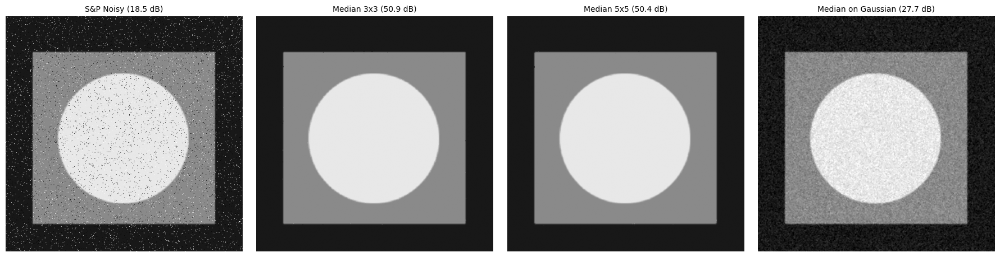

In [7]:
med_sp = cv2.medianBlur(noise_sp, 3)
med_sp5 = cv2.medianBlur(noise_sp, 5)
med_g = cv2.medianBlur(noise_gauss, 3)
show([noise_sp, med_sp, med_sp5, med_g],
     [f'S&P Noisy ({psnr(img,noise_sp):.1f} dB)', f'Median 3x3 ({psnr(img,med_sp):.1f} dB)', f'Median 5x5 ({psnr(img,med_sp5):.1f} dB)', f'Median on Gaussian ({psnr(img,med_g):.1f} dB)'],
     cols=4, figsize=(18,4.5))

## 7) Max and Min Filters

- **Max** (Dilation): takes the brightest pixel, so it removes **Pepper** but amplifies Salt.
- **Min** (Erosion): takes the darkest pixel, so it removes **Salt** but amplifies Pepper.

Each filter is applied to the noise it is meant to remove.

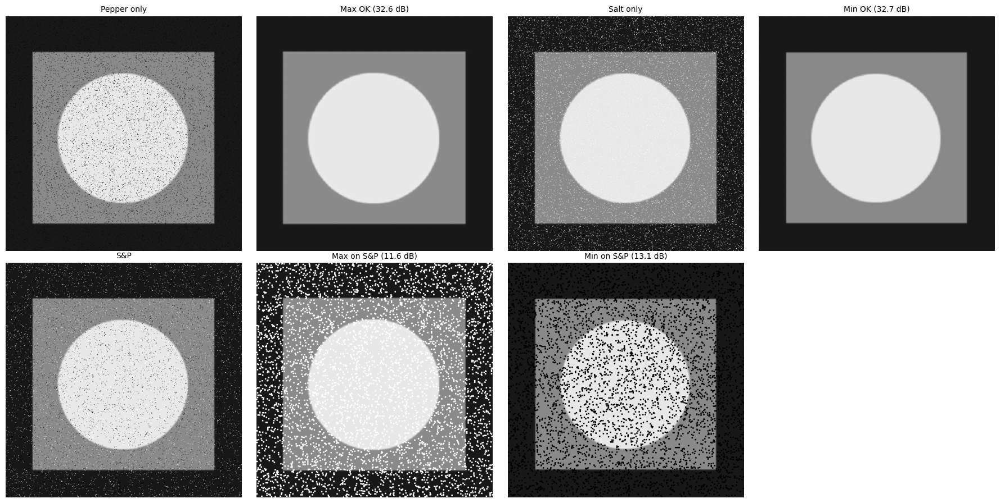

In [8]:
kernel = np.ones((3, 3), np.uint8)

max_on_pepper = cv2.dilate(pepper_img, kernel)   # Max removes Pepper
min_on_salt   = cv2.erode(salt_img, kernel)      # Min removes Salt
max_on_sp     = cv2.dilate(noise_sp, kernel)
min_on_sp     = cv2.erode(noise_sp, kernel)

show([pepper_img, max_on_pepper, salt_img, min_on_salt, noise_sp, max_on_sp, min_on_sp],
     ['Pepper only', f'Max OK ({psnr(img,max_on_pepper):.1f} dB)', 'Salt only', f'Min OK ({psnr(img,min_on_salt):.1f} dB)',
      'S&P', f'Max on S&P ({psnr(img,max_on_sp):.1f} dB)', f'Min on S&P ({psnr(img,min_on_sp):.1f} dB)'], cols=4, figsize=(18,9))

## 8) Mid-Point Filter

$$\hat f=\tfrac12\big[\max + \min\big]$$

Suits randomly distributed noise such as Gaussian and Uniform.

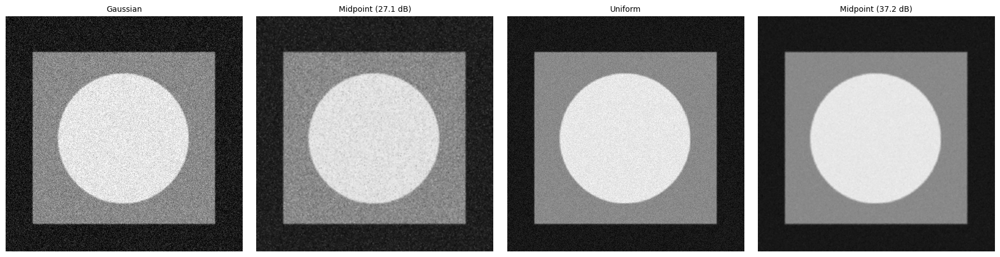

In [9]:
def midpoint_filter(image, kernel_size=3):
    k = np.ones((kernel_size, kernel_size), np.uint8)
    mx = cv2.dilate(image, k).astype(np.float64)
    mn = cv2.erode(image, k).astype(np.float64)
    return ((mx + mn) / 2).astype(np.uint8)

mp_g = midpoint_filter(noise_gauss, 3)
mp_u = midpoint_filter(noise_uni, 3)
show([noise_gauss, mp_g, noise_uni, mp_u],
     ['Gaussian', f'Midpoint ({psnr(img,mp_g):.1f} dB)', 'Uniform', f'Midpoint ({psnr(img,mp_u):.1f} dB)'], cols=4, figsize=(18,4.5))

## 9) Applying the Filters to the Real Salt & Pepper Images

The images `salt_Pepper.jpg` and `salt_Pepper2.jpg`:
- The first has mixed black and white dots (classic S&P), so the **Median** filter is the best fit.
- The second (the dome) is mostly **Pepper** (black dots) with a little Salt. **Contra-Harmonic with Q>0** or **Max** remove the black dots, but **Median** handles both types without amplifying either.

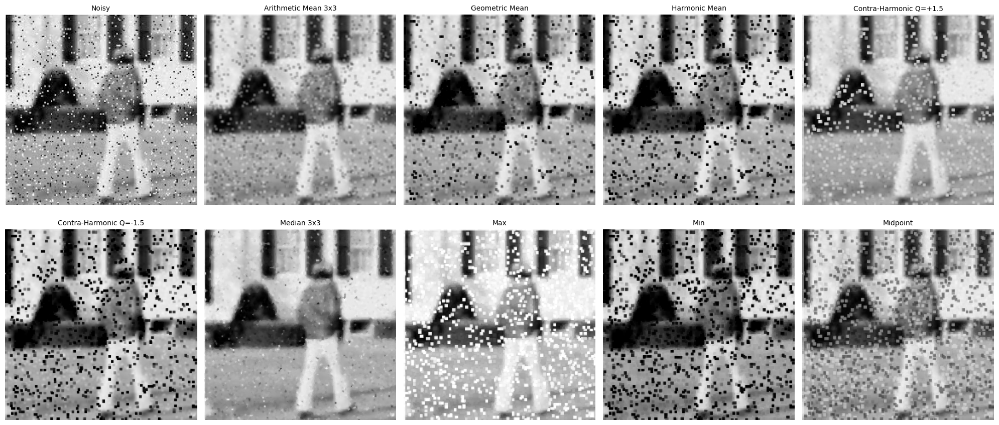

In [11]:
sp1 = cv2.imread('salt&Pepper.jpg', 0)
sp2 = cv2.imread('salt&Pepper2.jpg', 0)
assert sp1 is not None and sp2 is not None, "Upload salt_Pepper.jpg and salt_Pepper2.jpg"

def apply_all(im):
    results = {
        'Noisy': im,
        'Arithmetic Mean 3x3': cv2.blur(im, (3,3)),
        'Geometric Mean': geometric_mean_filter(im, 3),
        'Harmonic Mean': harmonic_mean_filter(im, 3),
        'Contra-Harmonic Q=+1.5': contra_harmonic_mean(im, 3, 1.5),
        'Contra-Harmonic Q=-1.5': contra_harmonic_mean(im, 3, -1.5),
        'Median 3x3': cv2.medianBlur(im, 3),
        'Max': cv2.dilate(im, np.ones((3,3),np.uint8)),
        'Min': cv2.erode(im, np.ones((3,3),np.uint8)),
        'Midpoint': midpoint_filter(im, 3),
    }
    show(list(results.values()), list(results.keys()), cols=5, figsize=(20,9))
    return results

r1 = apply_all(sp1)

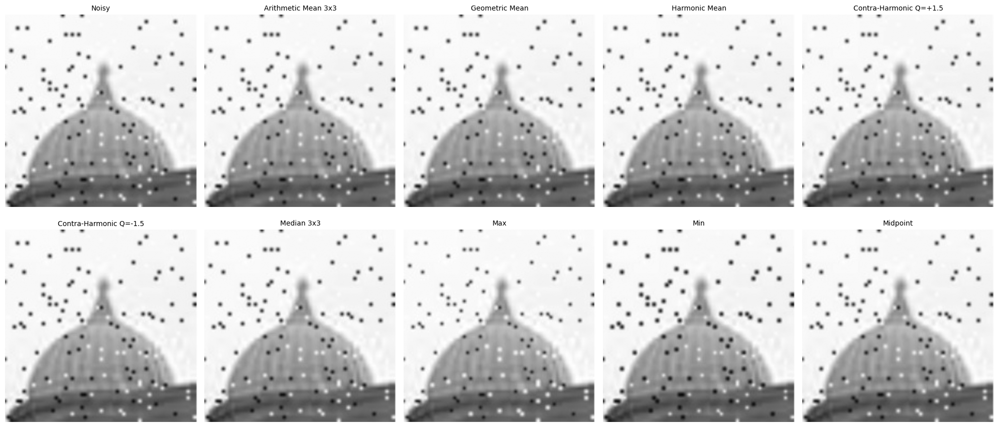

In [12]:
r2 = apply_all(sp2)

### Best result for each image

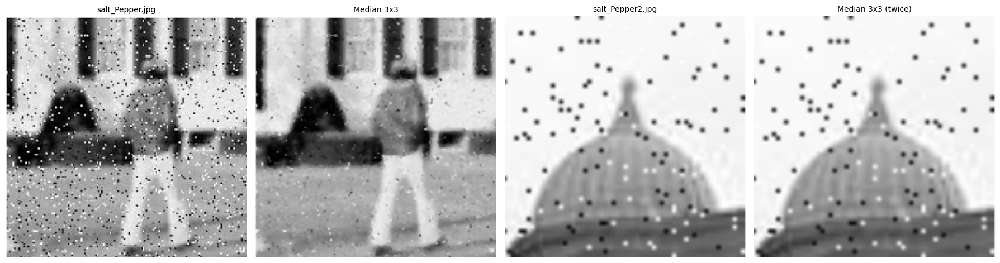

In [13]:
# Image 1: a 3x3 median removes both black and white dots
best1 = cv2.medianBlur(sp1, 3)

# Image 2: mostly Pepper -> apply the median twice to clean the remaining dots
best2 = cv2.medianBlur(sp2, 3)
best2 = cv2.medianBlur(best2, 3)

show([sp1, best1, sp2, best2], ['salt_Pepper.jpg', 'Median 3x3', 'salt_Pepper2.jpg', 'Median 3x3 (twice)'], cols=4, figsize=(18,5))

## Summary (which filter for which noise)

| Noise type | Best filter |
|---|---|
| Gaussian | Arithmetic / Geometric Mean |
| Uniform | Arithmetic / Geometric / Midpoint |
| Exponential | Geometric / Arithmetic Mean |
| Salt only | Harmonic, Contra-Harmonic (Q<0), Min |
| Pepper only | Contra-Harmonic (Q>0), Max |
| Salt & Pepper | **Median** (best); Harmonic/Geometric fail |
